<a href="https://colab.research.google.com/github/riyaduggal82-cell/PROJECT-OF-DATA-SCIENCE-BY-RIYA-CHAHAT/blob/main/PROJECT_OF_DATA_SCIENCE_BY_RIYA%26CHAHAT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

All Libraries Imported Successfully!
Please Upload Your Student Performance CSV Dataset


Saving student_performance_dataset.csv to student_performance_dataset (1).csv

Dataset Uploaded Successfully!


,Student_ID,Study_Hours,Attendance,Previous_Score,Assignments,Sleep_Hours,Final_Score,Result
0,1,7,73,99,2,7,83.70,Pass
1,2,4,72,57,3,4,56.49,Pass
2,3,8,57,55,3,6,65.77,Pass
3,4,5,96,54,9,9,75.94,Pass
4,5,7,86,41,7,9,78.41,Pass



Dataset Shape:
(1000, 8)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Student_ID      1000 non-null   int64  
 1   Study_Hours     1000 non-null   int64  
 2   Attendance      1000 non-null   int64  
 3   Previous_Score  1000 non-null   int64  
 4   Assignments     1000 non-null   int64  
 5   Sleep_Hours     1000 non-null   int64  
 6   Final_Score     1000 non-null   float64
 7   Result          1000 non-null   object 
dtypes: float64(1), int64(6), object(1)
memory usage: 62.6+ KB

Missing Values:
Student_ID        0
Study_Hours       0
Attendance        0
Previous_Score    0
Assignments       0
Sleep_Hours       0
Final_Score       0
Result            0
dtype: int64

Statistical Summary:


,Student_ID,Study_Hours,Attendance,Previous_Score,Assignments,Sleep_Hours,Final_Score
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,4.898000,75.304000,63.848000,5.403000,6.572000,68.013500
std,288.819436,2.603916,14.622976,20.252137,2.874866,1.727368,12.926851
min,1.000000,1.000000,50.000000,30.000000,1.000000,4.000000,20.970000
25%,250.750000,3.000000,63.000000,47.000000,3.000000,5.000000,59.442500
50%,500.500000,5.000000,75.000000,63.500000,5.000000,7.000000,68.025000
75%,750.250000,7.000000,88.000000,81.000000,8.000000,8.000000,77.292500
max,1000.000000,9.000000,100.000000,100.000000,10.000000,9.000000,100.000000


Data Cleaning Completed Successfully!


,Student_ID,Study_Hours,Attendance,Previous_Score,Assignments,Sleep_Hours,Final_Score,Result
0,1,7,73,99,2,7,83.70,Pass
1,2,4,72,57,3,4,56.49,Pass
2,3,8,57,55,3,6,65.77,Pass
3,4,5,96,54,9,9,75.94,Pass
4,5,7,86,41,7,9,78.41,Pass



STUDENT PERFORMANCE ANALYSIS
--------------------------------
Total Students: 1000
Average Score: 68.01
Highest Score: 100.0
Lowest Score: 20.97
Passed Students: 982
Failed Students: 18
Pass Percentage: 98.2 %


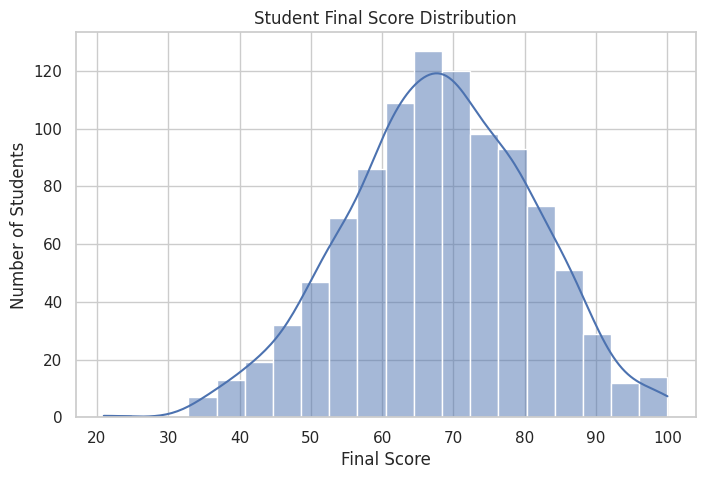

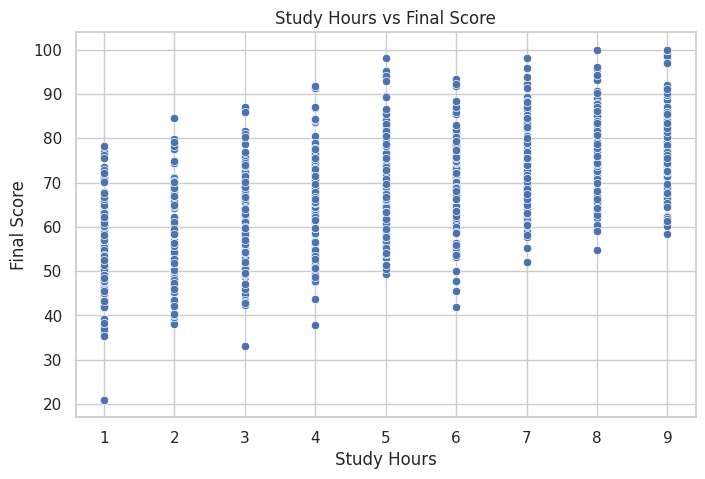

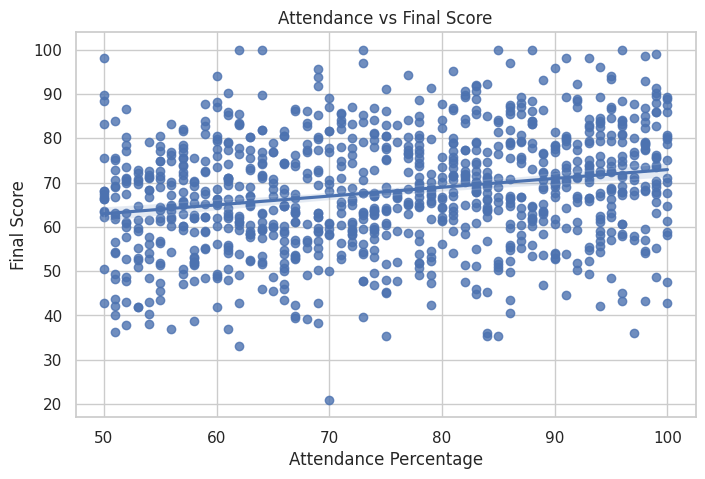

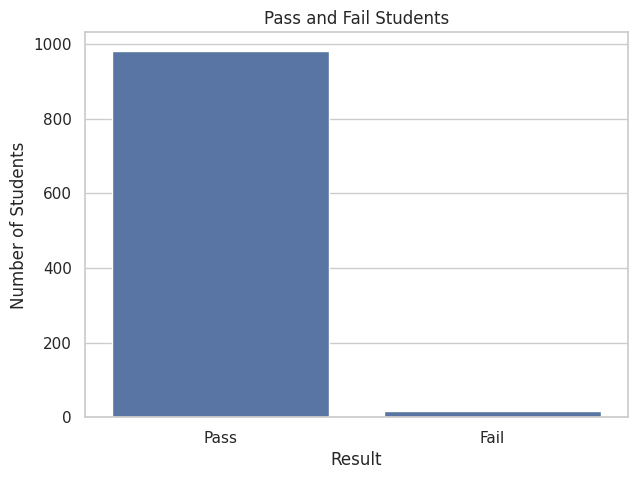

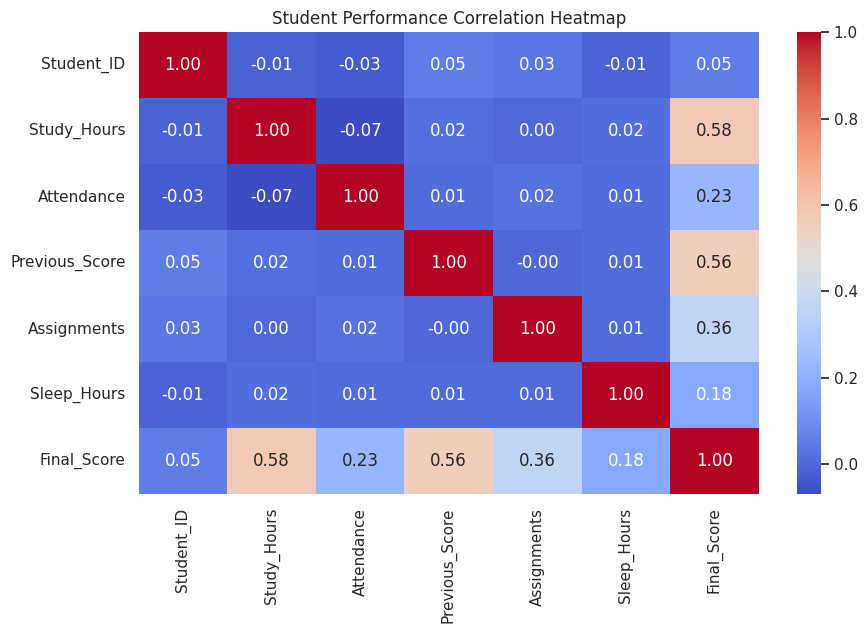


MACHINE LEARNING MODEL RESULTS
--------------------------------
Model Training Completed Successfully!
Mean Absolute Error: 5.04
Root Mean Squared Error: 6.2
R2 Score: 0.774


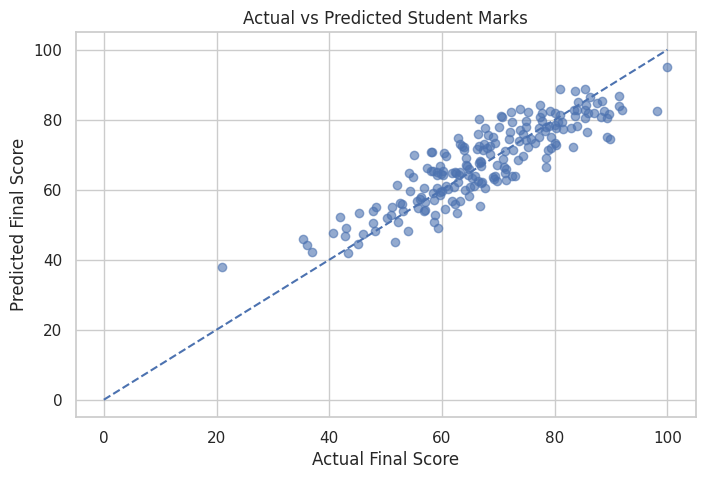

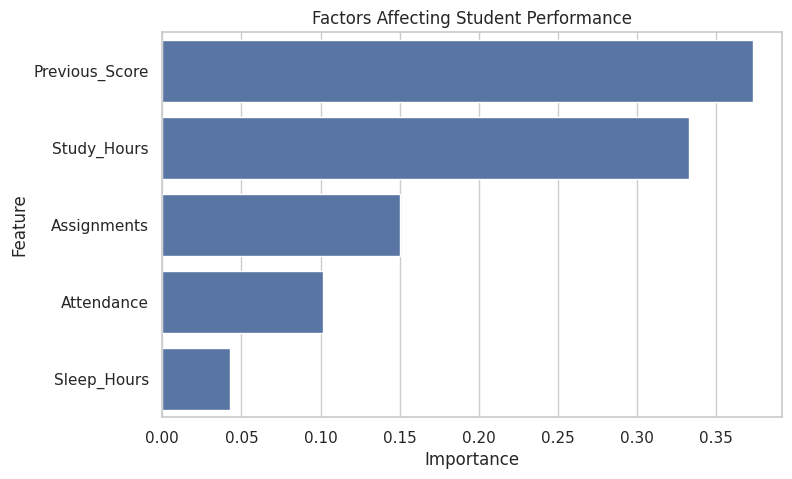

,Feature,Importance
2,Previous_Score,0.372926
0,Study_Hours,0.332681
3,Assignments,0.150181
1,Attendance,0.101715
4,Sleep_Hours,0.042496


Dropdown(description='Select Chart:', options=('Final Score Distribution', 'Study Hours Analysis', 'Attendance…

Output()

IntSlider(value=5, description='Study Hours:', max=10, min=1)

IntSlider(value=75, description='Attendance:', min=50)

IntSlider(value=60, description='Previous Score:', min=30)

... (3 outputs left out)

Output()


Project Completed Successfully!
Cleaned Dataset Saved Successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
# ==========================================================
# STUDENT PERFORMANCE ANALYSIS AND PREDICTION DASHBOARD
# BCA (AI & DATA SCIENCE) PROJECT
# BY RIYA AND CHAHAT


# ==========================================================
# STEP 1: IMPORT LIBRARIES
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets

from IPython.display import display, HTML, clear_output
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

sns.set_theme(style="whitegrid")

print("All Libraries Imported Successfully!")


# ==========================================================
# STEP 2: UPLOAD DATASET
# ==========================================================

print("Please Upload Your Student Performance CSV Dataset")

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("\nDataset Uploaded Successfully!")

display(df.head())


# ==========================================================
# STEP 3: DATASET INFORMATION
# ==========================================================

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())


# ==========================================================
# STEP 4: DATA CLEANING
# ==========================================================

df = df.drop_duplicates().copy()

required_columns = [
    "Student_ID",
    "Study_Hours",
    "Attendance",
    "Previous_Score",
    "Assignments",
    "Sleep_Hours",
    "Final_Score",
    "Result"
]

missing_columns = set(required_columns) - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Missing columns in dataset: {missing_columns}"
    )

numeric_columns = [
    "Study_Hours",
    "Attendance",
    "Previous_Score",
    "Assignments",
    "Sleep_Hours",
    "Final_Score"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=numeric_columns)

df["Result"] = np.where(
    df["Final_Score"] >= 40,
    "Pass",
    "Fail"
)

print("Data Cleaning Completed Successfully!")

display(df.head())


# ==========================================================
# STEP 5: STUDENT PERFORMANCE ANALYSIS
# ==========================================================

total_students = len(df)

average_score = df["Final_Score"].mean()

highest_score = df["Final_Score"].max()

lowest_score = df["Final_Score"].min()

passed_students = (
    df["Result"] == "Pass"
).sum()

failed_students = (
    df["Result"] == "Fail"
).sum()

pass_percentage = (
    passed_students / total_students * 100
)

print("\nSTUDENT PERFORMANCE ANALYSIS")

print("--------------------------------")

print("Total Students:", total_students)

print("Average Score:", round(average_score, 2))

print("Highest Score:", highest_score)

print("Lowest Score:", lowest_score)

print("Passed Students:", passed_students)

print("Failed Students:", failed_students)

print("Pass Percentage:", round(pass_percentage, 2), "%")


# ==========================================================
# STEP 6: FINAL SCORE DISTRIBUTION
# ==========================================================

plt.figure(figsize=(8, 5))

sns.histplot(
    df["Final_Score"],
    bins=20,
    kde=True
)

plt.title("Student Final Score Distribution")

plt.xlabel("Final Score")

plt.ylabel("Number of Students")

plt.show()


# ==========================================================
# STEP 7: STUDY HOURS ANALYSIS
# ==========================================================

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Study_Hours",
    y="Final_Score"
)

plt.title("Study Hours vs Final Score")

plt.xlabel("Study Hours")

plt.ylabel("Final Score")

plt.show()


# ==========================================================
# STEP 8: ATTENDANCE ANALYSIS
# ==========================================================

plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x="Attendance",
    y="Final_Score"
)

plt.title("Attendance vs Final Score")

plt.xlabel("Attendance Percentage")

plt.ylabel("Final Score")

plt.show()


# ==========================================================
# STEP 9: PASS AND FAIL ANALYSIS
# ==========================================================

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Result"
)

plt.title("Pass and Fail Students")

plt.xlabel("Result")

plt.ylabel("Number of Students")

plt.show()


# ==========================================================
# STEP 10: CORRELATION HEATMAP
# ==========================================================

plt.figure(figsize=(10, 6))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Student Performance Correlation Heatmap")

plt.show()


# ==========================================================
# STEP 11: MACHINE LEARNING MODEL
# ==========================================================

X = df[
    [
        "Study_Hours",
        "Attendance",
        "Previous_Score",
        "Assignments",
        "Sleep_Hours"
    ]
]

y = df["Final_Score"]


# Split Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


# Create Random Forest Model

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)


# Train Model

model.fit(X_train, y_train)


# Predict Test Data

predictions = model.predict(X_test)


# Model Evaluation

mae = mean_absolute_error(
    y_test,
    predictions
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        predictions
    )
)

r2 = r2_score(
    y_test,
    predictions
)


print("\nMACHINE LEARNING MODEL RESULTS")

print("--------------------------------")

print("Model Training Completed Successfully!")

print("Mean Absolute Error:", round(mae, 2))

print("Root Mean Squared Error:", round(rmse, 2))

print("R2 Score:", round(r2, 3))


# ==========================================================
# STEP 12: ACTUAL VS PREDICTED SCORE
# ==========================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    predictions,
    alpha=0.6
)

plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--"
)

plt.xlabel("Actual Final Score")

plt.ylabel("Predicted Final Score")

plt.title("Actual vs Predicted Student Marks")

plt.show()


# ==========================================================
# STEP 13: FEATURE IMPORTANCE
# ==========================================================

importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance": model.feature_importances_

})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Factors Affecting Student Performance")

plt.show()

display(importance)


# ==========================================================
# STEP 14: INTERACTIVE DASHBOARD
# ==========================================================

display(HTML("""
<div style="
background:#172554;
padding:25px;
border-radius:12px;
text-align:center;
color:white;
">

<h1>STUDENT PERFORMANCE DASHBOARD</h1>

<h3>Student Performance Analysis and Prediction</h3>

<p>BCA (AI & Data Science) Project</p>

</div>
"""))


# Dashboard Cards

cards = f"""

<div style="
display:flex;
flex-wrap:wrap;
gap:15px;
margin-top:20px;
">

<div style="
background:#dbeafe;
padding:20px;
border-radius:12px;
flex:1;
min-width:150px;
text-align:center;
color:#172554;
">

<h3>Total Students</h3>
<h1>{total_students}</h1>

</div>


<div style="
background:#dcfce7;
padding:20px;
border-radius:12px;
flex:1;
min-width:150px;
text-align:center;
color:#14532d;
">

<h3>Average Score</h3>
<h1>{average_score:.2f}</h1>

</div>


<div style="
background:#fef3c7;
padding:20px;
border-radius:12px;
flex:1;
min-width:150px;
text-align:center;
color:#78350f;
">

<h3>Passed Students</h3>
<h1>{passed_students}</h1>

</div>


<div style="
background:#fee2e2;
padding:20px;
border-radius:12px;
flex:1;
min-width:150px;
text-align:center;
color:#7f1d1d;
">

<h3>Failed Students</h3>
<h1>{failed_students}</h1>

</div>

</div>

"""

display(HTML(cards))


# ==========================================================
# STEP 15: INTERACTIVE DASHBOARD CHARTS
# ==========================================================

chart_dropdown = widgets.Dropdown(

    options=[

        "Final Score Distribution",

        "Study Hours Analysis",

        "Attendance Analysis",

        "Pass and Fail Analysis",

        "Correlation Heatmap"

    ],

    description="Select Chart:"

)

chart_output = widgets.Output()


def show_dashboard_chart(change=None):

    with chart_output:

        clear_output(wait=True)

        plt.figure(figsize=(9, 5))


        if chart_dropdown.value == "Final Score Distribution":

            sns.histplot(
                df["Final_Score"],
                bins=20,
                kde=True
            )

            plt.title("Final Score Distribution")


        elif chart_dropdown.value == "Study Hours Analysis":

            sns.scatterplot(
                data=df,
                x="Study_Hours",
                y="Final_Score"
            )

            plt.title("Study Hours vs Final Score")


        elif chart_dropdown.value == "Attendance Analysis":

            sns.regplot(
                data=df,
                x="Attendance",
                y="Final_Score"
            )

            plt.title("Attendance vs Final Score")


        elif chart_dropdown.value == "Pass and Fail Analysis":

            sns.countplot(
                data=df,
                x="Result"
            )

            plt.title("Pass and Fail Students")


        elif chart_dropdown.value == "Correlation Heatmap":

            sns.heatmap(
                df.select_dtypes(include="number").corr(),
                annot=True,
                cmap="coolwarm",
                fmt=".2f"
            )

            plt.title("Correlation Heatmap")


        plt.tight_layout()

        plt.show()


chart_dropdown.observe(
    show_dashboard_chart,
    names="value"
)

display(chart_dropdown)

display(chart_output)

show_dashboard_chart()


# ==========================================================
# STEP 16: STUDENT PERFORMANCE PREDICTION
# ==========================================================

display(HTML("""
<hr>

<h2 style="color:#2563eb;">
Student Performance Prediction
</h2>

<p>
Enter student details to predict the final examination score.
</p>
"""))


# Input Widgets

study = widgets.IntSlider(

    value=5,

    min=1,

    max=10,

    description="Study Hours:"

)


attendance = widgets.IntSlider(

    value=75,

    min=50,

    max=100,

    description="Attendance:"

)


previous = widgets.IntSlider(

    value=60,

    min=30,

    max=100,

    description="Previous Score:"

)


assignments = widgets.IntSlider(

    value=5,

    min=1,

    max=10,

    description="Assignments:"

)


sleep = widgets.IntSlider(

    value=7,

    min=4,

    max=9,

    description="Sleep Hours:"

)


button = widgets.Button(

    description="Predict Performance",

    button_style="success"

)


prediction_output = widgets.Output()


# Prediction Function

def predict_student(b):

    with prediction_output:

        clear_output(wait=True)

        student_data = pd.DataFrame([{

            "Study_Hours": study.value,

            "Attendance": attendance.value,

            "Previous_Score": previous.value,

            "Assignments": assignments.value,

            "Sleep_Hours": sleep.value

        }])


        predicted_score = model.predict(
            student_data
        )[0]


        predicted_score = np.clip(
            predicted_score,
            0,
            100
        )


        result = (
            "PASS"
            if predicted_score >= 40
            else "FAIL"
        )


        display(HTML(f"""

        <div style="
        background:#e0f2fe;
        padding:20px;
        border-radius:12px;
        color:#172554;
        ">

        <h2>Prediction Result</h2>

        <h3>Predicted Final Score:
        {predicted_score:.2f}/100</h3>

        <h3>Estimated Result: {result}</h3>

        </div>

        """))


button.on_click(predict_student)


display(

    study,

    attendance,

    previous,

    assignments,

    sleep,

    button,

    prediction_output

)


# ==========================================================
# STEP 17: DOWNLOAD CLEANED DATASET
# ==========================================================

df.to_csv(
    "student_performance_analysis_output.csv",
    index=False
)

print("\nProject Completed Successfully!")

print("Cleaned Dataset Saved Successfully!")

files.download(
    "student_performance_analysis_output.csv"
)


# ==========================================================
# END OF PROJECT
# ==========================================================